# 02 · Models, results and business insights
`train.py` trains everything (5-fold CV, tuning, Keras) and writes `models/metrics.json`.
This notebook shows those results, checks the saved models on the test set, and turns them into recommendations.

In [1]:
import sys
sys.path.append("..")          # lets the notebook import data.py, predict.py, ...
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (8, 4)})

import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline
from data import FEATURES, load_shipments, fit_rules, training_rows, build_preprocessor
metrics = json.load(open("../models/metrics.json"))
df = load_shipments()
train_raw, test_raw = train_test_split(df, test_size=0.2, random_state=42)   # same split as train.py
rules = fit_rules(train_raw)
train, test = training_rows(train_raw, rules), training_rows(test_raw, rules)
print(len(train), "train rows |", len(test), "test rows | caps", rules)

1566 train rows | 389 test rows | caps {'weight_cap_kg': 98.9, 'cost_cap_usd': 729.3525}


## 1 · Baselines and tuned models: 5-fold CV mean absolute error (USD)

In [2]:
pd.Series(metrics['cv_mae']).sort_values().round(2).to_frame('cv_mae_usd')

,cv_mae_usd
XGBoost (tuned),13.00
Keras MLP,14.83
Random Forest,15.05
Linear Regression,15.68
Decision Tree,20.83
Mean baseline,80.55


Every model beats the mean baseline (USD 80.55) by far. Tuned XGBoost settings:

In [3]:
metrics['xgb_params']

{'subsample': 1.0,
 'reg_lambda': 0.1,
 'n_estimators': 600,
 'min_child_weight': 1,
 'max_depth': 2,
 'learning_rate': 0.03,
 'colsample_bytree': 1.0}

## 2 · The deep learning model (TensorFlow / Keras)
Dense 128 → Dropout 0.2 → Dense 64 → Dropout 0.2 → 1 output (cost). One-hot + scaled inputs, standardised target,
Huber loss (robust to noisy prices), Adam, early stopping. **Why not a CNN?** A shipment row has no neighbouring
pixels or time steps; dense layers are the right deep-learning shape for tables.

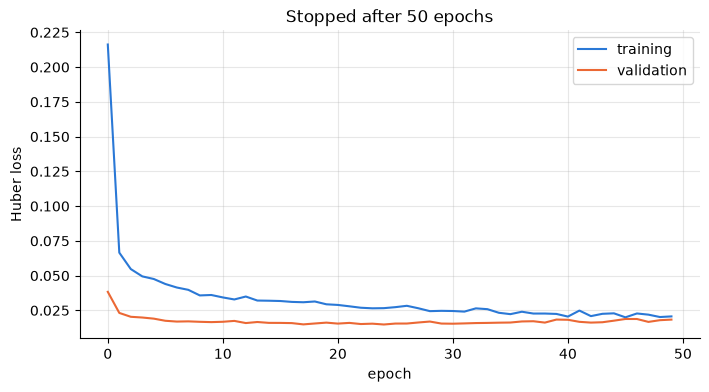

In [4]:
history = json.load(open("../models/keras_history.json"))
plt.plot(history["loss"], label="training", color=BLUE); plt.plot(history["val_loss"], label="validation", color=ORANGE)
plt.xlabel("epoch"); plt.ylabel("Huber loss"); plt.legend(); plt.title(f"Stopped after {len(history['loss'])} epochs"); plt.show()

## 3 · Test set (20%, untouched until now)

In [5]:
results = pd.DataFrame(metrics["test"]).T.round(3)
results

,mae,median_abs_error,r2
Linear Regression,16.680,13.121,0.922
XGBoost (tuned),13.539,9.584,0.936
Keras MLP,14.549,9.671,0.933


Tuned XGBoost cuts the cost error by 18.8% vs linear regression


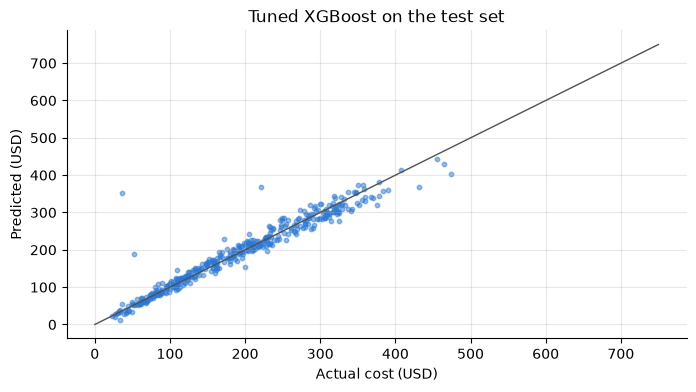

In [6]:
lin, xgb = metrics["test"]["Linear Regression"]["mae"], metrics["test"]["XGBoost (tuned)"]["mae"]
print(f"Tuned XGBoost cuts the cost error by {100 * (lin - xgb) / lin:.1f}% vs linear regression")
model = joblib.load("../models/xgb_cost.joblib")
pred = model.predict(test[FEATURES])
plt.scatter(test["Cost"], pred, s=10, alpha=0.5, color=BLUE)
plt.plot([0, 750], [0, 750], color="#52514e", linewidth=1)
plt.xlabel("Actual cost (USD)"); plt.ylabel("Predicted (USD)"); plt.title("Tuned XGBoost on the test set"); plt.show()

## 4 · What drives the predicted price? (permutation importance)

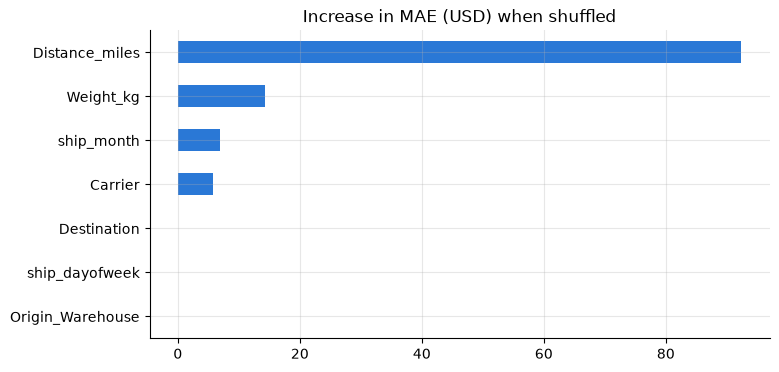

Distance_miles      92.38
Weight_kg           14.25
ship_month           6.86
Carrier              5.70
Destination          0.07
ship_dayofweek       0.00
Origin_Warehouse    -0.02
dtype: float64

In [7]:
from sklearn.inspection import permutation_importance
imp = permutation_importance(model, test[FEATURES], test["Cost"], n_repeats=10, random_state=42,
                             scoring="neg_mean_absolute_error")
importance = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = importance.plot.barh(color=BLUE); ax.set(title="Increase in MAE (USD) when shuffled"); plt.show()
importance.sort_values(ascending=False).round(2)

## 5 · Can delays be predicted? (signal check)

In [8]:
done = df[df["Status"] != "In Transit"]
pipe = Pipeline([("prep", build_preprocessor()), ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))])
auc = cross_val_score(pipe, done[FEATURES], done["is_exception"], scoring="roc_auc",
                      cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean()
print(f"Delay/exception ROC-AUC = {auc:.2f}  (0.5 = coin flip)")

Delay/exception ROC-AUC = 0.52  (0.5 = coin flip)


Close to a coin flip, so no delay model is shipped. Recommendation: collect tracking scans, weather and hub load first.

## 6 · Business insight: learned rate card and savings simulation

In [9]:
data = pd.concat([train, test])
card = {}
for carrier, g in data.groupby("Carrier"):
    fit = LinearRegression().fit(g[["Distance_miles", "Weight_kg"]].fillna(g["Weight_kg"].median()), g["Cost"])
    card[carrier] = fit.predict(pd.DataFrame({"Distance_miles": [1000], "Weight_kg": [20]}))[0]
pd.Series(card).sort_values().round(2).to_frame("USD for 1,000 miles, 20 kg")

,"USD for 1,000 miles, 20 kg"
USPS,141.19
OnTrac,149.01
Amazon Logistics,149.30
LaserShip,149.61
UPS,156.63
FedEx,165.37
DHL,171.20


In [10]:
quotes = {}
for carrier in sorted(data["Carrier"].unique()):
    X = data[FEATURES].copy()
    X["Carrier"] = carrier
    quotes[carrier] = model.predict(X)
quotes = pd.DataFrame(quotes, index=data.index)
used = np.array([quotes.loc[i, c] for i, c in zip(data.index, data["Carrier"])])
best = quotes.min(axis=1).values
print(f"Predicted spend with the carriers used: USD {used.sum():,.0f}")
print(f"With the cheapest carrier every time:   USD {best.sum():,.0f}")
print(f"Potential saving: USD {(used - best).sum():,.0f} ({100 * (used - best).sum() / used.sum():.1f}%), upper bound")
quotes.idxmin(axis=1).value_counts()

Predicted spend with the carriers used: USD 387,272
With the cheapest carrier every time:   USD 356,951
Potential saving: USD 30,321 (7.8%), upper bound


USPS                1717
LaserShip            198
Amazon Logistics      31
OnTrac                 9
Name: count, dtype: int64

## 7 · Recommendations
1. **Quote every carrier at booking** with the Carrier Advisor and default to the cheapest (upper-bound saving above; check carrier capacity on the biggest lanes first).
2. **Renegotiate with the most expensive carriers** using the rate card.
3. **Don't rank carriers on reliability yet**: the differences are not significant.
4. **Validate data at entry**: impossible dates, zero weights and extreme costs got through.
5. **Collect delay drivers** so a delay-risk model becomes possible.